# 02 · Circuits and Entanglement

**Scaling and its wall.** Multiple qubits live in a $2^N$-dimensional space built by tensor products. Entanglement — a Bell state — is a correlation that *no* product of single-qubit states can reproduce. And the price of all this is the exponential: the statevector doubles in size with every qubit you add.

This is the link to `curse_of_dimensionality_101`: the $2^N$ state space is the exponential that makes quantum interesting in principle and simulation hard in practice.

In [ ]:
import sys, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Resolve the repo root whether this runs from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

FIG = ROOT / "outputs" / "figures"
DATA = ROOT / "outputs" / "data"
FIG.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)


def _ser(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, complex):
        return {"re": float(o.real), "im": float(o.imag)}
    raise TypeError(f"not JSON-serializable: {type(o)!r}")


def save_json(name, obj):
    """Save textual/numerical results to outputs/data/<name>."""
    path = DATA / name
    path.write_text(json.dumps(obj, indent=2, default=_ser))
    print("saved", path.relative_to(ROOT))


def save_fig(fig, name):
    """Save a figure as PNG to outputs/figures/<name>."""
    path = FIG / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))


def amp_list(state):
    """A statevector as a JSON-friendly list of {re, im} amplitudes."""
    return [{"re": float(a.real), "im": float(a.imag)} for a in np.asarray(state)]


plt.rcParams.update({"figure.figsize": (7.0, 4.0), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)
print("repo root:", ROOT)


repo root: /workspaces/quantum_ml_101


## Two qubits: a 4-vector, a Bell state

$H$ on qubit 0 then $\mathrm{CNOT}(0, 1)$ makes the Bell state $(|00\rangle + |11\rangle)/\sqrt2$. The outcomes 00 and 11 each have probability 1/2; 01 and 10 never occur. The two qubits are perfectly correlated.

Bell amplitudes: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
probabilities: {'00': np.float64(0.5), '01': np.float64(0.0), '10': np.float64(0.0), '11': np.float64(0.5)}


saved outputs/figures/02_bell_probabilities.png


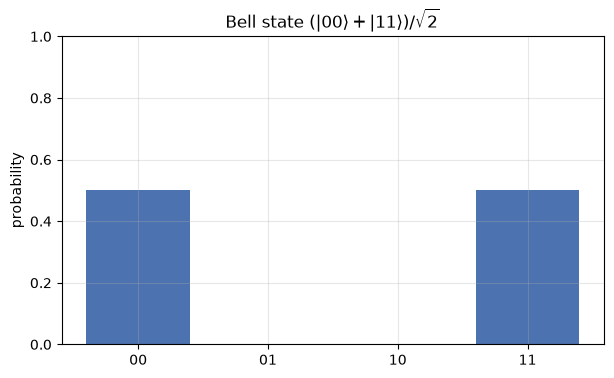

In [2]:
from src.sim.statevector import StateVector
from src.sim import gates

sv = StateVector(2).apply(gates.H, (0,)).apply(gates.CNOT, (0, 1))
labels = ['00', '01', '10', '11']
probs = sv.probabilities()
print('Bell amplitudes:', np.round(sv.state, 3))
print('probabilities:', dict(zip(labels, np.round(probs, 3))))

fig, ax = plt.subplots()
ax.bar(labels, probs, color='#4c72b0')
ax.set_ylim(0, 1)
ax.set_ylabel('probability')
ax.set_title(r'Bell state $(|00\rangle + |11\rangle)/\sqrt{2}$')
save_fig(fig, '02_bell_probabilities.png')

## Why it is *entangled*: the single-qubit view is maximally mixed

Trace out qubit 1 and look at qubit 0 alone (its reduced density matrix). For a product state this stays pure (purity $\mathrm{Tr}\,\rho^2 = 1$). For the Bell state it is maximally mixed: $\rho_0 = \tfrac12 I$, purity $= 0.5$. No single-qubit description can carry the correlation — that is entanglement.

In [3]:
def reduced_qubit0(state2):
    m = np.asarray(state2).reshape(2, 2)   # [q0, q1]
    return m @ m.conj().T                  # trace out q1

rho0 = reduced_qubit0(sv.state)
purity = float(np.real(np.trace(rho0 @ rho0)))
eigs = np.linalg.eigvalsh(rho0).real
print('reduced rho_0:\n', np.round(rho0, 3))
print('eigenvalues:', np.round(eigs, 3), '| purity:', round(purity, 3))

# Compare to a product state H|0> ⊗ H|0>, which stays pure.
prod = StateVector(2).apply(gates.H, (0,)).apply(gates.H, (1,))
purity_prod = float(np.real(np.trace(reduced_qubit0(prod.state) @ reduced_qubit0(prod.state))))
print('product-state purity:', round(purity_prod, 3))

save_json('02_bell_state.json', {
    'amplitudes': amp_list(sv.state),
    'probabilities': dict(zip(labels, probs.tolist())),
    'reduced_qubit0_eigenvalues': eigs.tolist(),
    'bell_purity': purity,
    'product_state_purity': purity_prod,
})

reduced rho_0:
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
eigenvalues: [0.5 0.5] | purity: 0.5
product-state purity: 1.0
saved outputs/data/02_bell_state.json


## The exponential wall: memory and time vs qubit count

A statevector is $2^N$ complex128 numbers at 16 bytes each. Memory **doubles** with every qubit. We measure the actual array size and the wall-clock time to apply a layer of Hadamards, and watch both ride the $2^N$ curve.

In [4]:
from src.analysis.scaling import scan, statevector_bytes

counts = list(range(2, 21))
measured = scan(counts)
memory = [measured[n]['bytes'] for n in counts]
seconds = [measured[n]['seconds'] for n in counts]

save_json('02_scaling.json', {str(n): measured[n] for n in counts})
print('20 qubits:', statevector_bytes(20) / 1e6, 'MB')

saved outputs/data/02_scaling.json
20 qubits: 16.777216 MB


saved outputs/figures/02_scaling_memory.png


saved outputs/figures/02_scaling_time.png


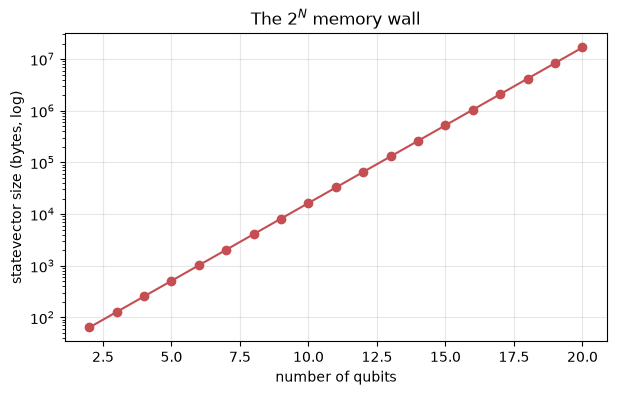

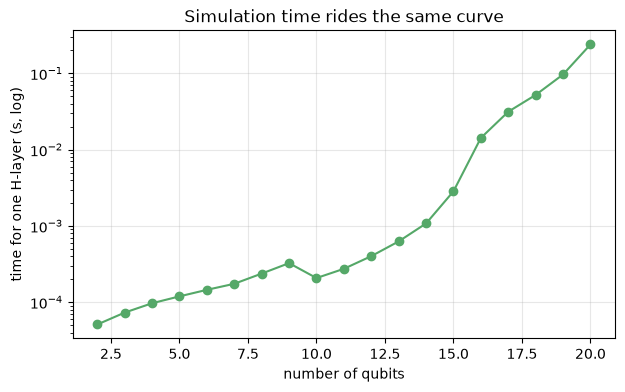

In [5]:
fig, ax = plt.subplots()
ax.semilogy(counts, memory, 'o-', color='#c44e52')
ax.set_xlabel('number of qubits')
ax.set_ylabel('statevector size (bytes, log)')
ax.set_title('The $2^N$ memory wall')
save_fig(fig, '02_scaling_memory.png')

fig, ax = plt.subplots()
ax.semilogy(counts, seconds, 'o-', color='#55a868')
ax.set_xlabel('number of qubits')
ax.set_ylabel('time for one H-layer (s, log)')
ax.set_title('Simulation time rides the same curve')
save_fig(fig, '02_scaling_time.png')

## The landmarks that make it visceral

16 MB at 20 qubits, ~1 GB at 26, and at 40 qubits more memory than exists on Earth. You cannot simulate your way to scale — which is exactly why the quantum models we *can* run are small.

In [6]:
landmarks = {
    n: {
        'bytes': statevector_bytes(n),
        'human': f'{statevector_bytes(n) / 1e6:.1f} MB' if n < 30 else f'{statevector_bytes(n) / 1e12:.1f} TB',
    }
    for n in (10, 20, 26, 30, 40)
}
for n, d in landmarks.items():
    print(f'{n:>3} qubits -> {d["human"]}')

save_json('02_scaling_landmarks.json', {
    'landmarks': {str(n): landmarks[n] for n in landmarks},
    'note': '40 qubits is ~17.6 TB of complex128 amplitudes, more than any single machine holds.',
})

 10 qubits -> 0.0 MB
 20 qubits -> 16.8 MB
 26 qubits -> 1073.7 MB
 30 qubits -> 0.0 TB
 40 qubits -> 17.6 TB
saved outputs/data/02_scaling_landmarks.json


## Takeaways

- $N$ qubits = a $2^N$ complex vector; gates act by tensor-structured matmul.
- Entanglement is real and measurable: the Bell state's single-qubit view is maximally mixed (purity 0.5), unreachable by any product state.
- Memory and time both double per qubit. This is the wall.

Next: **03 — Feature Maps and Kernels**, the first head-to-head with classical ML.